In [4]:
!pip install pylatexenc
!pip install qiskit
!pip install qiskit-aer
!pip install qiskit qiskit-aer matplotlib numpy

STEP 1. Classical Data
Age            : 25
Purchase Score : 82

STEP 2. Normalize
Input Feature
[0.25, 0.82]

STEP 3. Feature Map
     ┌──────────────────────────┐
q_0: ┤0                         ├
     │  ZZFeatureMap(x[0],x[1]) │
q_1: ┤1                         ├
     └──────────────────────────┘


/tmp/ipykernel_2084/382931482.py:45: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=2, reps=1)


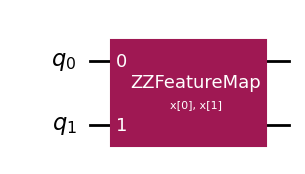


STEP 4. Variational Circuit
     ┌──────────────────────────────────────┐
q_0: ┤0                                     ├
     │  RealAmplitudes(θ[0],θ[1],θ[2],θ[3]) │
q_1: ┤1                                     ├
     └──────────────────────────────────────┘


/tmp/ipykernel_2084/382931482.py:58: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(num_qubits=2, reps=1)


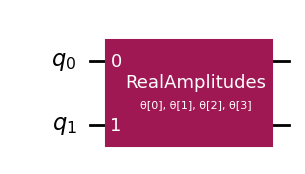


STEP 5. Compose Circuit
     ┌──────────────────────────┐┌──────────────────────────────────────┐
q_0: ┤0                         ├┤0                                     ├
     │  ZZFeatureMap(x[0],x[1]) ││  RealAmplitudes(θ[0],θ[1],θ[2],θ[3]) │
q_1: ┤1                         ├┤1                                     ├
     └──────────────────────────┘└──────────────────────────────────────┘


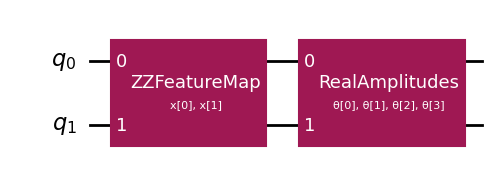


STEP 6. Measurement


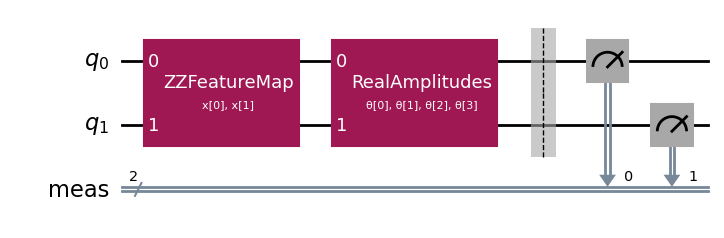


STEP 7. Parameter List
x[0]
x[1]
θ[0]
θ[1]
θ[2]
θ[3]

STEP 8. Parameter Binding
x[0]                 -> 0.791
x[1]                 -> 0.525
θ[0]                 -> 0.045
θ[1]                 -> 0.370
θ[2]                 -> 0.508
θ[3]                 -> 0.256

STEP 9. Simulation
Measurement Result
{'01': 147, '11': 338, '10': 268, '00': 271}

STEP 10. Histogram


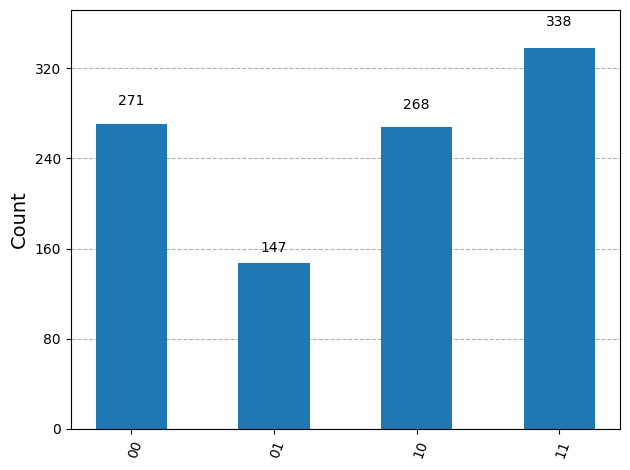


Mini QML Pipeline Completed Successfully!


In [6]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt

from qiskit.circuit.library import ZZFeatureMap, RealAmplitudes
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit.visualization import plot_histogram

# =====================================================
# STEP 1. Classical Data 준비
# =====================================================
print("=" * 60)
print("STEP 1. Classical Data")
print("=" * 60)

age = 25
purchase_score = 82

print(f"Age            : {age}")
print(f"Purchase Score : {purchase_score}")

# =====================================================
# STEP 2. Feature 정규화
# =====================================================
print("\n" + "=" * 60)
print("STEP 2. Normalize")
print("=" * 60)

x1 = age / 100
x2 = purchase_score / 100
x = [x1, x2]

print("Input Feature")
print(x)

# =====================================================
# STEP 3. Feature Map 생성
# =====================================================
print("\n" + "=" * 60)
print("STEP 3. Feature Map")
print("=" * 60)

feature_map = ZZFeatureMap(feature_dimension=2, reps=1)
print(feature_map)

fig = feature_map.draw("mpl")
display(fig)  # 코랩 출력용 display 활용

# =====================================================
# STEP 4. Variational Circuit 생성
# =====================================================
print("\n" + "=" * 60)
print("STEP 4. Variational Circuit")
print("=" * 60)

ansatz = RealAmplitudes(num_qubits=2, reps=1)
print(ansatz)

fig = ansatz.draw("mpl")
display(fig)

# =====================================================
# STEP 5. QML Pipeline 생성 (Feature Map + Ansatz)
# =====================================================
print("\n" + "=" * 60)
print("STEP 5. Compose Circuit")
print("=" * 60)

qml_circuit = feature_map.compose(ansatz)
print(qml_circuit)

fig = qml_circuit.draw("mpl")
display(fig)

# =====================================================
# STEP 6. Measurement 추가
# =====================================================
print("\n" + "=" * 60)
print("STEP 6. Measurement")
print("=" * 60)

qml_circuit.measure_all()
fig = qml_circuit.draw("mpl")
display(fig)

# =====================================================
# STEP 7. Parameter 확인
# =====================================================
print("\n" + "=" * 60)
print("STEP 7. Parameter List")
print("=" * 60)

parameters = list(qml_circuit.parameters)
for p in parameters:
    print(p)

# =====================================================
# STEP 8. Parameter Binding
# =====================================================
print("\n" + "=" * 60)
print("STEP 8. Parameter Binding")
print("=" * 60)

parameter_values = {}
for p in parameters:
    value = np.random.random()
    parameter_values[p] = value
    print(f"{str(p):20} -> {value:.3f}")

bound_circuit = qml_circuit.assign_parameters(parameter_values)

# =====================================================
# STEP 9. Circuit 실행 (Simulation)
# =====================================================
print("\n" + "=" * 60)
print("STEP 9. Simulation")
print("=" * 60)

simulator = AerSimulator()
compiled = transpile(bound_circuit, simulator)
job = simulator.run(compiled, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement Result")
print(counts)

# =====================================================
# STEP 10. Histogram
# =====================================================
print("\n" + "=" * 60)
print("STEP 10. Histogram")
print("=" * 60)

fig = plot_histogram(counts)
display(fig)

# =====================================================
# STEP 11. 실습 종료
# =====================================================
print("\n" + "=" * 60)
print("Mini QML Pipeline Completed Successfully!")
print("=" * 60)